# 013. 출근시간대 추가분석

종일 분석에 이어 **승차시각 06:00:00 이상~10:00:00 미만(09:59:59까지 포함)**의 특성을 추가로 확인한다. 기존 012, 원자료, 기존 결과표는 수정하지 않는다. 표·그림은 화면에 출력하고, 별도 CSV·그림 파일은 저장하지 않는다.

| 분석 | 종속변수·비교값 | 표본 |
|---|---|---:|
| 종일 광역버스 OLS | 2025−2024 승차건수 변화량 | 126개 |
| 출근 광역버스 OLS | 출근시간 승차건수 변화량 | 설명변수가 정의되는 113개 |
| 종일 / 출근 GTX역행 마을·시내버스 OLS | 2025년 해당 시간대 GTX역행 이용건수 | 각각 126개 |
| 종일 / 출근 Spearman 순위상관 | 광역버스 변화량 ↔ 2025년 GTX역행 이용건수 | 각각 126개 |

광역버스 출근시간 **집계는 126개 전체**를 유지한다. 2024년 출근시간 승차가 없는 13개는 버스 통행시간과 경쟁 목적지 비율을 정의할 수 없어 **광역버스 출근 OLS에서만 제외**한다. 미정의 값을 0분·0%로 대체하지 않는다. 상관분석에는 두 비교값이 모두 있으므로 126개 전체를 사용한다.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display

ROOT_013 = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'config.py').is_file() and (p / 'code').is_dir())
TABLES_013 = ROOT_013 / 'results/analysis/feeder_bus/tables'
ORDER_013 = ['운정중앙', '킨텍스', '대곡']
STATION_COLORS_013 = {'운정중앙':'#3264A8', '킨텍스':'#D18C32', '대곡':'#359475'}
TIME_LABEL_013 = '06:00~09:59:59'
for font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
             Path(r'C:\Windows\Fonts\malgun.ttf'), Path('/Library/Fonts/NanumGothic.ttf')]:
    if font.is_file():
        fm.fontManager.addfont(str(font))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(font)).get_name()
        break
plt.rcParams.update({'axes.unicode_minus':False, 'font.size':12, 'figure.dpi':110,
                     'axes.titlesize':15, 'axes.labelsize':12})
pd.set_option('display.max_columns', 30)

def axes_style_013(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.2)

def is_morning_013(times):
    # 9시대 포함: integer hour 6, 7, 8, 9. 10:00:00 is excluded.
    return times.dt.hour.ge(6) & times.dt.hour.lt(10)

# 경계시각 확인: 05:59:59, 06:00:00, 09:00:00, 09:59:59, 10:00:00
_time_test_013 = pd.Series(pd.to_datetime(['2024-10-17 05:59:59','2024-10-17 06:00:00',
    '2024-10-17 09:00:00','2024-10-17 09:59:59','2024-10-17 10:00:00']))
assert is_morning_013(_time_test_013).tolist() == [False, True, True, True, False]

base_013 = pd.read_csv(ROOT_013/'data/final/gtx_a/S1_126격자_건수기준_기초표.csv', encoding='utf-8-sig').set_index('셀 ID')
cell_stops_013 = pd.read_csv(ROOT_013/'data/processed/gtx_a/16_새데이터_공급구조유지_250m격자.csv', dtype=str, encoding='utf-8-sig')
feeder_013 = pd.read_csv(TABLES_013/'H11a_격자별_공급구조_GTX역행.csv', encoding='utf-8-sig').set_index('셀 ID')
for frame in [base_013,feeder_013]:
    assert len(frame)==126 and frame.index.is_unique
assert set(base_013.index)==set(feeder_013.index)==set(cell_stops_013['셀 ID'].astype(int))
feeder_013=feeder_013.reindex(base_013.index)
assert feeder_013['권역'].eq(base_013['nearest_station']).all()
for source,target in [('board_2024','광역 2024'),('board_2025','광역 2025'),('change','Δ광역')]:
    np.testing.assert_allclose(base_013[source],feeder_013[target])
assert base_013.groupby('nearest_station').size().reindex(ORDER_013).tolist()==[63,26,37]
print('프로젝트:', ROOT_013)
print('출근시간:', TIME_LABEL_013, '· 9시대 포함 · 126개 격자 연결 확인')

프로젝트: /Users/keumkyounghoon/Desktop/Gachon/3-2/UROP
출근시간: 06:00~09:59:59 · 9시대 포함 · 126개 격자 연결 확인


## 1. 원자료에서 출근시간 광역버스 변수 재계산

- 비교 날짜를 **2024-10-17 / 2025-11-06**으로 고정한다. 2025-10-16 자료와 혼동하지 않는다.
- 승차건수는 교통카드 **행 수**이며 `utztn_nope` 합계를 사용하지 않는다. 임의 중복 제거도 하지 않는다.
- 출근 경쟁 목적지 비율: **2024년 출근시간 승차 중 하차좌표가 있는 건수**를 분모로 하고, 기존과 같은 연신내역·서울역 반경 1km 하차 건수를 분자로 한다.
- 출근 평균 버스 통행시간: **2024년 출근시간 승차** 중 `brdg_hr/60`이 0분 초과~240분 이하인 기록의 단순 평균이다. 도착시각이 10시 이후여도 승차시각이 출근시간이면 포함한다.
- 보행시간·인구·연면적·주거지역·IC 거리는 기존 S1 값을 유지한다.

**영업일 처리:** 조회일·운행일(`query_date`, `opr_ymd`)을 기준으로 원자료를 유지한다. 다음 날 자정 이후~6시 미만 기록이 포함될 수 있으며, 종일 집계에서는 유지하고 출근시간 집계에서는 시간 조건에 따라 포함하지 않는다.

In [2]:
def haversine_013(lat,lon,target_lat,target_lon):
    lat,lon,target_lat,target_lon=map(np.radians,(lat,lon,target_lat,target_lon))
    a=np.sin((target_lat-lat)/2)**2+np.cos(lat)*np.cos(target_lat)*np.sin((target_lon-lon)/2)**2
    return 6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))

COMPETING_013 = [(37.619001,126.921008),(37.5547,126.9707)]
def competition_013(frame):
    lat=pd.to_numeric(frame['하차위도'],errors='coerce')
    lon=pd.to_numeric(frame['하차경도'],errors='coerce')
    known=lat.notna() & lon.notna()
    hit=pd.Series(False,index=frame.index)
    for la,lo in COMPETING_013:
        hit |= haversine_013(lat,lon,la,lo).le(1.0)
    den=frame.loc[known].groupby('셀 ID').size().reindex(base_013.index,fill_value=0)
    num=frame.loc[known & hit].groupby('셀 ID').size().reindex(base_013.index,fill_value=0)
    return 100*num/den.replace(0,np.nan),den,num

morning_013=base_013.copy()
quality_rows_013=[]
for year,filename,date in [
    (2024,'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv','20241017'),
    (2025,'gtx_a_transport_card_20251106_raw_with_coords.csv','20251106')]:
    card=pd.read_csv(ROOT_013/'data/raw/gtx_a/transport_card'/filename,dtype=str,encoding='utf-8-sig')
    assert card['query_date'].eq(date).all() and card['opr_ymd'].eq(date).all()
    lookup=pd.DataFrame([(int(row['셀 ID']),sid) for _,row in cell_stops_013.iterrows()
                        for sid in re.findall(r'\d{6,}',row[f'{year}년 정류장 ID'])],
                       columns=['셀 ID','승차정류장ID'])
    assert not lookup['승차정류장ID'].duplicated().any()
    selected=card.merge(lookup,on='승차정류장ID',how='inner',validate='many_to_one')
    times=pd.to_datetime(selected['ride_dt'],format='%Y%m%d%H%M%S',errors='raise')
    # 영업일 원자료에는 다음 날 자정 이후 기록도 포함될 수 있다. 원자료를 삭제하지 않는다.
    ride_date=times.dt.normalize()
    service_day=pd.Timestamp(date)
    assert (ride_date.eq(service_day) | (ride_date.eq(service_day+pd.Timedelta(days=1)) & times.dt.hour.lt(6))).all()
    all_counts=selected.groupby('셀 ID').size().reindex(base_013.index,fill_value=0)
    np.testing.assert_array_equal(all_counts,base_013[f'board_{year}'])
    morning=selected.loc[is_morning_013(times)].copy()
    morning_013[f'출근_승차건수_{year}']=morning.groupby('셀 ID').size().reindex(base_013.index,fill_value=0)
    if year==2024:
        # 재집계 로직이 기존 S1을 재현하는지 종일 값부터 확인한다.
        full_share,_,_=competition_013(selected)
        np.testing.assert_allclose(full_share.fillna(0),base_013['competing_share'],atol=1e-10)
        full_minutes=pd.to_numeric(selected['brdg_hr'],errors='raise')/60
        full_valid=selected.loc[full_minutes.gt(0)&full_minutes.le(240)].copy()
        full_valid['minutes']=full_minutes.loc[full_valid.index]
        np.testing.assert_allclose(full_valid.groupby('셀 ID')['minutes'].mean().reindex(base_013.index),
                                   base_013['bus_time_mean'],atol=1e-10)
        morning_013['출근_경쟁목적지비율'],known_counts_013,comp_counts_013=competition_013(morning)
        morning['minutes']=pd.to_numeric(morning['brdg_hr'],errors='raise')/60
        valid=morning.loc[morning['minutes'].gt(0)&morning['minutes'].le(240)]
        morning_013['출근_평균버스통행시간']=valid.groupby('셀 ID')['minutes'].mean().reindex(base_013.index)
        print('2024 출근 하차좌표 확인:',int(known_counts_013.sum()),'건 / 경쟁 목적지:',int(comp_counts_013.sum()),'건')
    quality_rows_013.append({'연도':year,'종일_분석격자_건수':len(selected),'출근_분석격자_건수':len(morning)})

morning_013['출근_변화량']=morning_013['출근_승차건수_2025']-morning_013['출근_승차건수_2024']
np.testing.assert_array_equal(morning_013['출근_변화량'],feeder_013['Δ광역 출근'])
print('출근 광역버스 변화량: 기존 H11a와 126개 모두 일치')
display(pd.DataFrame(quality_rows_013))

2024 출근 하차좌표 확인: 3098 건 / 경쟁 목적지: 390 건
출근 광역버스 변화량: 기존 H11a와 126개 모두 일치


,연도,종일_분석격자_건수,출근_분석격자_건수
0,2024,7110,3098
1,2025,5517,2286


## 2. 126개 격자의 광역버스 출근시간 변화

권역 변화율은 **권역별 건수 합계의 변화율**이다. 2024년 0건 격자의 개별 변화율은 정의하지 않지만, 건수와 변화량 집계에는 포함한다.

,격자수,개통전,개통후,변화량,변화율(%)
nearest_station,,,,,
운정중앙,63.0,1304.0,848.0,-456.0,-34.97
킨텍스,26.0,1354.0,959.0,-395.0,-29.17
대곡,37.0,440.0,479.0,39.0,8.86
전체,126.0,3098.0,2286.0,-812.0,-26.21


,격자 수
구분,
감소,73
유지,16
증가,37


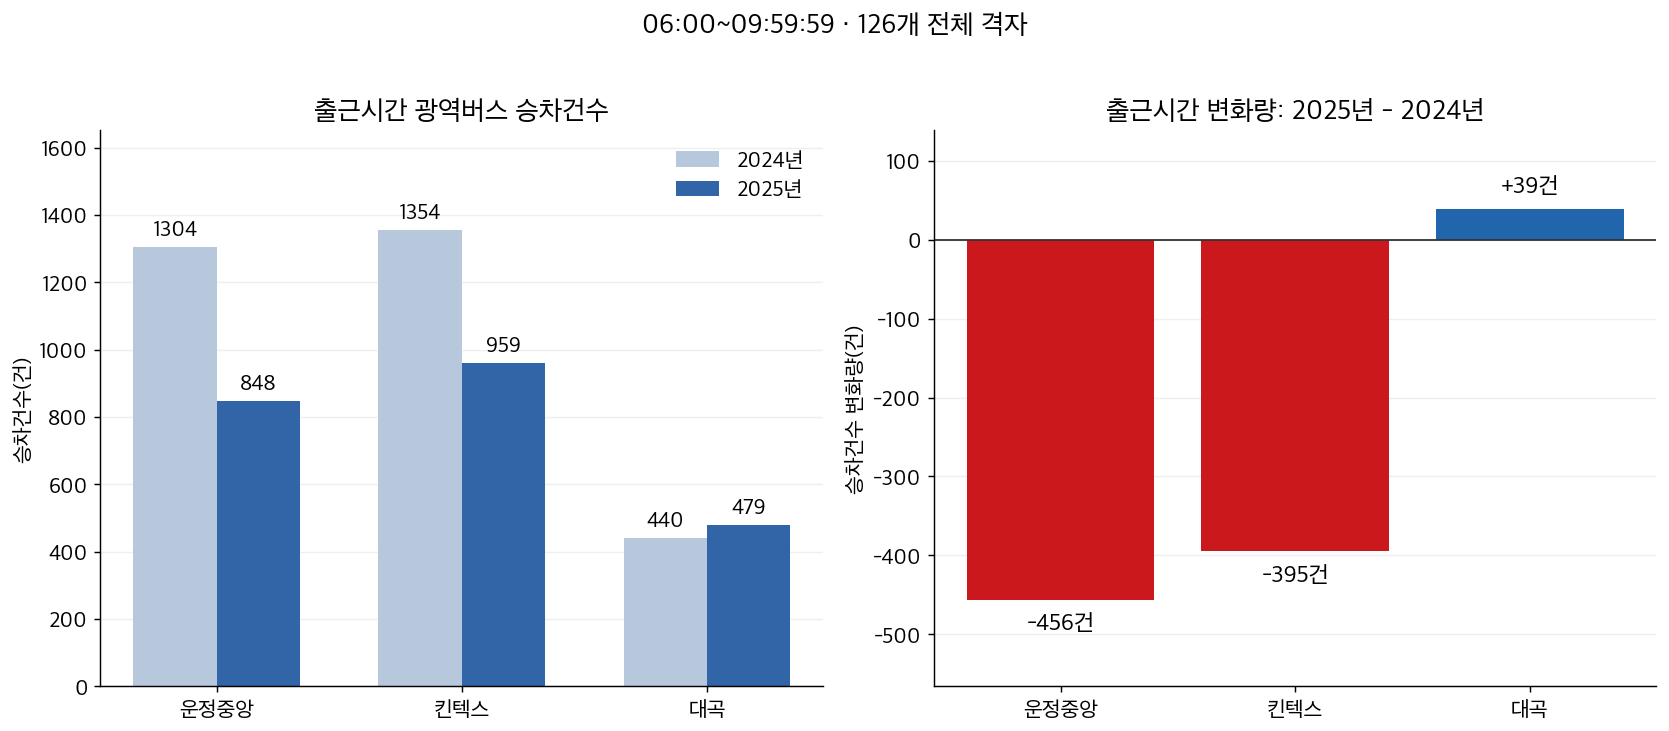

In [3]:
broad_region_013=morning_013.groupby('nearest_station').agg(
    격자수=('출근_변화량','size'), 개통전=('출근_승차건수_2024','sum'),
    개통후=('출근_승차건수_2025','sum'), 변화량=('출근_변화량','sum')).reindex(ORDER_013)
broad_region_013['변화율(%)']=100*broad_region_013['변화량']/broad_region_013['개통전'].replace(0,np.nan)
broad_display_013=broad_region_013.copy()
broad_display_013.loc['전체',['격자수','개통전','개통후','변화량']]=broad_region_013[['격자수','개통전','개통후','변화량']].sum()
broad_display_013.loc['전체','변화율(%)']=100*broad_display_013.loc['전체','변화량']/broad_display_013.loc['전체','개통전']
display(broad_display_013.round(2))
display(morning_013.assign(구분=np.select([morning_013['출근_변화량'].lt(0),morning_013['출근_변화량'].gt(0)],
                                      ['감소','증가'],default='유지'))['구분']
        .value_counts().reindex(['감소','유지','증가'],fill_value=0).rename('격자 수').to_frame())
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
x=np.arange(3);w=.34
for off,col,lab,color in [(-w/2,'개통전','2024년','#B8C8DC'),(w/2,'개통후','2025년','#3264A8')]:
    bars=axes[0].bar(x+off,broad_region_013[col],w,label=lab,color=color)
    axes[0].bar_label(bars,padding=5,fontsize=12,fontweight='bold')
axes[0].set_xticks(x,ORDER_013);axes[0].legend(frameon=False);axes[0].set_ylabel('승차건수(건)')
axes[0].set_title('출근시간 광역버스 승차건수');axes[0].set_ylim(0,broad_region_013[['개통전','개통후']].max().max()*1.22)
vals=broad_region_013['변화량'];bars=axes[1].bar(ORDER_013,vals,color=['#CB181D' if v<0 else '#2166AC' if v>0 else '#AAAAAA' for v in vals])
axes[1].axhline(0,color='#333333',lw=1)
for bar,v in zip(bars,vals):
    axes[1].annotate(f'{int(v):+,}건',(bar.get_x()+bar.get_width()/2,v),xytext=(0,-7 if v<0 else 7),
                     textcoords='offset points',ha='center',va='top' if v<0 else 'bottom',fontsize=13,fontweight='bold')
axes[1].set_ylim(min(0,vals.min())-110,max(0,vals.max())+100);axes[1].set_ylabel('승차건수 변화량(건)')
axes[1].set_title('출근시간 변화량: 2025년 - 2024년')
for ax in axes:axes_style_013(ax)
fig.suptitle(TIME_LABEL_013+' · 126개 전체 격자',fontsize=15,y=1.02)
fig.tight_layout();plt.show()

## 3. 광역버스 OLS: 종일 주 분석과 출근시간 추가 분석

종속변수는 **승차건수 변화량**이다. 두 모형 모두 7변수·상수항·HC3를 유지하며 보행시간과 연면적만 `log(1+x)`로 변환한다. 출근 모형은 **통행시간·경쟁 목적지 비율까지 2024년 출근시간 값**으로 바꾼다.

종일 126개와 출근 113개는 표본·종속변수의 시간 범위가 다르다. 유의 변수 개수나 R²를 비교해 더 우수한 모형을 선택하지 않는다. 13개 제외는 결과나 유의성에 따른 선택이 아니라 설명변수 미정의에 따른 처리다.

In [4]:
morning_013['log_walk']=np.log1p(morning_013['walk_min'])
morning_013['log_floor']=np.log1p(morning_013['2024년 건축물 연면적(천㎡)'])
BROAD_X_013=['log_walk','pop_20_50','log_floor','주거지역 비율(%)','competing_share','bus_time_mean','ic_access']
BROAD_LABELS_013={'log_walk':'log(1+보행시간)','pop_20_50':'20~50대 인구','log_floor':'log(1+건축물 연면적)',
                  '주거지역 비율(%)':'주거지역 비율','competing_share':'GTX 경쟁 목적지 비율',
                  'bus_time_mean':'평균 버스 통행시간','ic_access':'IC 도로거리'}
X_day_013=morning_013[BROAD_X_013].copy()
X_morn_013=X_day_013.copy()
X_morn_013['competing_share']=morning_013['출근_경쟁목적지비율']
X_morn_013['bus_time_mean']=morning_013['출근_평균버스통행시간']
assert np.isfinite(X_day_013.to_numpy()).all()
mask_broad_morning_013=pd.Series(np.isfinite(X_morn_013.to_numpy()).all(axis=1),index=morning_013.index)
assert mask_broad_morning_013.eq(morning_013['출근_승차건수_2024'].gt(0)).all()
excluded_013=morning_013.loc[~mask_broad_morning_013,
    ['nearest_station','출근_승차건수_2024','출근_승차건수_2025','출근_변화량','출근_경쟁목적지비율','출근_평균버스통행시간']]
print('광역버스 출근 OLS에서만 제외:',len(excluded_013),'개 (집계·순위상관에는 포함)')
display(excluded_013.reset_index())

def fit_hc3_013(y,X):
    assert y.index.equals(X.index)
    assert np.isfinite(y.to_numpy()).all() and np.isfinite(X.to_numpy()).all()
    return sm.OLS(y.astype(float),sm.add_constant(X.astype(float),has_constant='add'),missing='raise').fit(cov_type='HC3')

def coefficient_rows_013(fit,model,labels):
    ci=fit.conf_int()
    return [{'모형':model,'변수':labels.get(key,'상수항' if key=='const' else key),'계수':fit.params[key],
             'HC3 표준오차':fit.bse[key],'p값':fit.pvalues[key],'95% CI 하한':ci.loc[key,0],
             '95% CI 상한':ci.loc[key,1],'5% 유의':bool(fit.pvalues[key]<.05)} for key in fit.params.index]

def fit_row_013(fit,label):
    return {'모형':label,'격자 수':int(fit.nobs),'R²':fit.rsquared,'수정 R²':fit.rsquared_adj,
            'HC3 F값':float(fit.fvalue),'모형 p값':float(fit.f_pvalue)}

broad_day_fit_013=fit_hc3_013(morning_013['change'],X_day_013)
broad_morning_fit_013=fit_hc3_013(morning_013.loc[mask_broad_morning_013,'출근_변화량'],X_morn_013.loc[mask_broad_morning_013])
broad_coeff_013=pd.DataFrame(coefficient_rows_013(broad_day_fit_013,'종일',BROAD_LABELS_013)+
                            coefficient_rows_013(broad_morning_fit_013,'출근',BROAD_LABELS_013))
broad_fits_013=pd.DataFrame([fit_row_013(broad_day_fit_013,'종일'),fit_row_013(broad_morning_fit_013,'출근')])
assert int(broad_day_fit_013.nobs)==126 and int(broad_morning_fit_013.nobs)==113
print('종속변수: 광역버스 승차건수 변화량(건)')
for period in ['종일','출근']:
    print(period);display(broad_coeff_013.loc[broad_coeff_013['모형'].eq(period)].round(6))
display(broad_fits_013.round(6))

광역버스 출근 OLS에서만 제외: 13 개 (집계·순위상관에는 포함)
종속변수: 광역버스 승차건수 변화량(건)
종일
출근


,셀 ID,nearest_station,출근_승차건수_2024,출근_승차건수_2025,출근_변화량,출근_경쟁목적지비율,출근_평균버스통행시간
0,1962,대곡,0,1,1,NaN,NaN
1,7368,대곡,0,2,2,NaN,NaN
2,8805,대곡,0,1,1,NaN,NaN
3,9285,대곡,0,0,0,NaN,NaN
4,14004,대곡,0,2,2,NaN,NaN
5,76,운정중앙,0,2,2,NaN,NaN
6,2295,운정중앙,0,0,0,NaN,NaN
7,4714,운정중앙,0,2,2,NaN,NaN
8,4768,운정중앙,0,1,1,NaN,NaN
9,7262,운정중앙,0,0,0,NaN,NaN


,모형,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,5% 유의
0,종일,상수항,-109.288968,47.680695,0.021900,-202.741412,-15.836524,True
1,종일,log(1+보행시간),26.586377,9.924675,0.007388,7.134372,46.038381,True
2,종일,20~50대 인구,0.012250,0.011579,0.290078,-0.010444,0.034944,False
3,종일,log(1+건축물 연면적),-7.798366,7.209205,0.279375,-21.928149,6.331417,False
4,종일,주거지역 비율,0.195835,0.195253,0.315871,-0.186854,0.578525,False
5,종일,GTX 경쟁 목적지 비율,-0.249535,0.123035,0.042543,-0.490678,-0.008391,True
6,종일,평균 버스 통행시간,-0.233219,0.223053,0.295756,-0.670394,0.203956,False
7,종일,IC 도로거리,-1.154513,0.992123,0.244554,-3.099037,0.790012,False


,모형,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,5% 유의
8,출근,상수항,-45.874652,12.791925,0.000336,-70.946364,-20.802940,True
9,출근,log(1+보행시간),13.879078,2.975334,0.000003,8.047530,19.710626,True
10,출근,20~50대 인구,0.002698,0.002860,0.345494,-0.002908,0.008304,False
11,출근,log(1+건축물 연면적),-4.001710,2.545892,0.115990,-8.991566,0.988147,False
12,출근,주거지역 비율,0.123427,0.056262,0.028250,0.013156,0.233698,True
13,출근,GTX 경쟁 목적지 비율,-0.114159,0.050373,0.023435,-0.212889,-0.015429,True
14,출근,평균 버스 통행시간,-0.257116,0.151028,0.088672,-0.553125,0.038893,False
15,출근,IC 도로거리,-1.470878,0.519899,0.004667,-2.489861,-0.451895,True


,모형,격자 수,R²,수정 R²,HC3 F값,모형 p값
0,종일,126,0.263265,0.219560,2.904976,0.007728
1,출근,113,0.305846,0.259569,4.013881,0.000625


In [5]:
EXPECTED_013={'log_walk':1,'pop_20_50':-1,'log_floor':-1,'주거지역 비율(%)':-1,
              'competing_share':-1,'bus_time_mean':-1,'ic_access':-1}
hypotheses_013=[]
for key in BROAD_X_013:
    p=float(broad_morning_fit_013.pvalues[key]);coef=float(broad_morning_fit_013.params[key])
    hypotheses_013.append({'변수':BROAD_LABELS_013[key],'가설 방향':'+' if EXPECTED_013[key]>0 else '−',
        '종일 계수':broad_day_fit_013.params[key],'종일 p값':broad_day_fit_013.pvalues[key],
        '출근 계수':coef,'출근 p값':p,'출근 가설 일치':bool(np.sign(coef)==EXPECTED_013[key]),
        '출근 유의수준':'5% 유의' if p<.05 else '10%만 유의' if p<.10 else '비유의'})
hypotheses_013=pd.DataFrame(hypotheses_013)
display(hypotheses_013.round(6))
print('출근 5% 유의 변수:',', '.join(hypotheses_013.loc[hypotheses_013['출근 p값'].lt(.05),'변수']))
print('출근 유의 변수 수: 5% =',int(hypotheses_013['출근 p값'].lt(.05).sum()),
      '/ 10% =',int(hypotheses_013['출근 p값'].lt(.10).sum()))
print('양(+)의 계수는 다른 조건을 조정했을 때 변화량이 높다는 뜻이며, 실제 증가를 반드시 의미하지 않음.')

출근 5% 유의 변수: log(1+보행시간), 주거지역 비율, GTX 경쟁 목적지 비율, IC 도로거리
출근 유의 변수 수: 5% = 4 / 10% = 5
양(+)의 계수는 다른 조건을 조정했을 때 변화량이 높다는 뜻이며, 실제 증가를 반드시 의미하지 않음.


,변수,가설 방향,종일 계수,종일 p값,출근 계수,출근 p값,출근 가설 일치,출근 유의수준
0,log(1+보행시간),+,26.586377,0.007388,13.879078,0.000003,True,5% 유의
1,20~50대 인구,−,0.012250,0.290078,0.002698,0.345494,False,비유의
2,log(1+건축물 연면적),−,-7.798366,0.279375,-4.001710,0.115990,True,비유의
3,주거지역 비율,−,0.195835,0.315871,0.123427,0.028250,False,5% 유의
4,GTX 경쟁 목적지 비율,−,-0.249535,0.042543,-0.114159,0.023435,True,5% 유의
5,평균 버스 통행시간,−,-0.233219,0.295756,-0.257116,0.088672,True,10%만 유의
6,IC 도로거리,−,-1.154513,0.244554,-1.470878,0.004667,True,5% 유의


## 4. GTX역행 마을·시내버스: 종일·출근 이용과 변화

기존 H11a의 출근 열은 **06:00~09:59:59** 집계다. `s10_11_feeder_supply_comparable.py` 계열의 승차시각 `hour.between(6,9)` 정의이며 이번 광역버스 원자료 재집계와 격자별 출근 변화량이 일치함을 위에서 확인했다.

마을·시내버스는 분석격자 정류장에서 승차하여 GTX역명 정류장에 하차한 기록이다. **개별 승객이 GTX를 실제 이용했는지 확인한 자료가 아니다.** 특히 대곡은 다른 철도로 환승했을 수도 있다. 운정중앙은 개통 전 역 정류장 부재 등 공급구조가 달라 개통 전 0건을 감소율·전환율 계산의 분모로 쓰지 않는다.

,격자수,종일2024,종일2025,출근2024,출근2025,출근 변화량,2025 출근 비율(%)
권역,,,,,,,
운정중앙,63,1.0,672.0,0.0,488.0,488.0,72.62
킨텍스,26,62.0,113.0,17.0,41.0,24.0,36.28
대곡,37,72.0,230.0,36.0,117.0,81.0,50.87


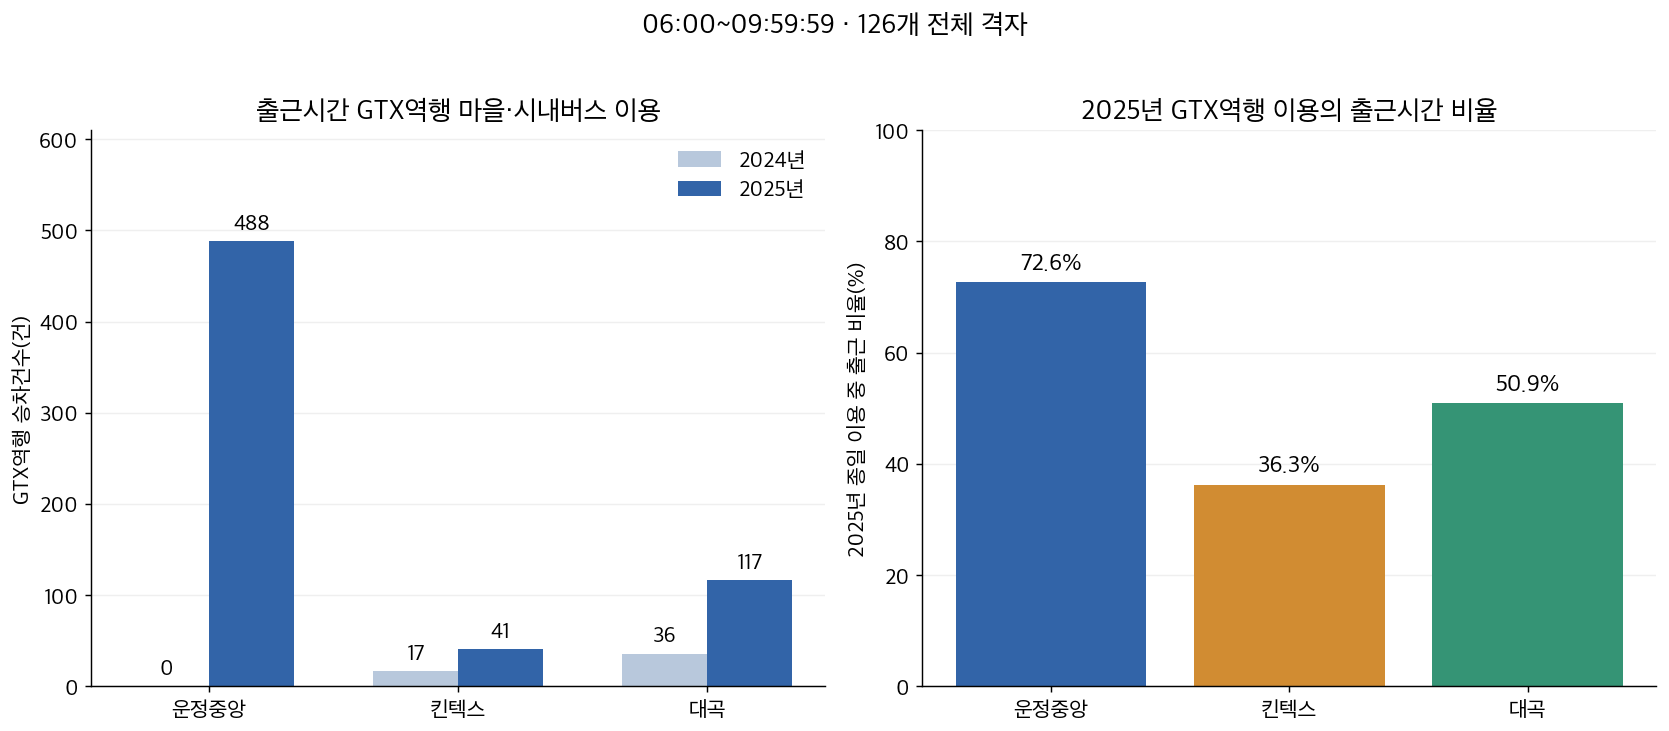

In [6]:
feeder_region_013=feeder_013.groupby('권역').agg(
    격자수=('GTX역행 2025','size'), 종일2024=('GTX역행 2024','sum'),종일2025=('GTX역행 2025','sum'),
    출근2024=('GTX역행 2024 출근','sum'),출근2025=('GTX역행 2025 출근','sum')).reindex(ORDER_013)
feeder_region_013['출근 변화량']=feeder_region_013['출근2025']-feeder_region_013['출근2024']
feeder_region_013['2025 출근 비율(%)']=100*feeder_region_013['출근2025']/feeder_region_013['종일2025'].replace(0,np.nan)
display(feeder_region_013.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,5.5));x=np.arange(3);w=.34
for off,col,lab,color in [(-w/2,'출근2024','2024년','#B8C8DC'),(w/2,'출근2025','2025년','#3264A8')]:
    bars=axes[0].bar(x+off,feeder_region_013[col],w,label=lab,color=color)
    axes[0].bar_label(bars,padding=5,fontsize=12,fontweight='bold')
axes[0].set_xticks(x,ORDER_013);axes[0].set_ylim(0,feeder_region_013['출근2025'].max()*1.25)
axes[0].set_ylabel('GTX역행 승차건수(건)');axes[0].set_title('출근시간 GTX역행 마을·시내버스 이용');axes[0].legend(frameon=False)
bars=axes[1].bar(ORDER_013,feeder_region_013['2025 출근 비율(%)'],color=[STATION_COLORS_013[s] for s in ORDER_013])
axes[1].bar_label(bars,labels=[f'{v:.1f}%' for v in feeder_region_013['2025 출근 비율(%)']],padding=5,fontsize=13,fontweight='bold')
axes[1].set_ylim(0,100);axes[1].set_ylabel('2025년 종일 이용 중 출근 비율(%)');axes[1].set_title('2025년 GTX역행 이용의 출근시간 비율')
for ax in axes:axes_style_013(ax)
fig.suptitle(TIME_LABEL_013+' · 126개 전체 격자',fontsize=15,y=1.02)
fig.tight_layout();plt.show()

## 5. 마을·시내버스 OLS: 개통 후 이용 수준

종속변수는 각각 **2025년 종일 / 2025년 출근 GTX역행 이용건수**다. 광역버스의 변화량 회귀와 추정 대상이 다르다. 두 시간대 모두 126개를 사용하고, 이용이 0건인 격자도 포함한다.

설명변수는 기존 6개 그대로다: `log(1+보행시간)`, **2025년** 20~50대 인구, `log(1+연면적)`, 주거지역 비율, 1km 내 기존 철도역 수, 운정중앙 더미. 운정 더미는 여러 권역 특성을 함께 반영하므로 환승센터만의 인과효과로 해석하지 않는다.

In [7]:
population_013=pd.read_csv(TABLES_013/'H14_격자별_20~50대인구_2025.csv',encoding='utf-8-sig').set_index('셀 ID').reindex(base_013.index)
rail_013=pd.read_csv(ROOT_013/'data/processed/gtx_a/feeder_bus/support/feature_expansion/S5_후보변수_126격자.csv',encoding='utf-8-sig').set_index('셀 ID').reindex(base_013.index)
X_feeder_013=feeder_013[['log(1+GTX역 보행시간)','log(1+건축물 연면적)','주거지역 비율(%)']].copy()
X_feeder_013['20~50대 인구 2025(명)']=population_013['20~50대 인구 2025(명)']
X_feeder_013['1km 안 기존 철도역 수']=rail_013['n_rail_1km']
X_feeder_013['운정 더미']=feeder_013['권역'].eq('운정중앙').astype(int)
FEEDER_X_013=['log(1+GTX역 보행시간)','20~50대 인구 2025(명)','log(1+건축물 연면적)',
              '주거지역 비율(%)','1km 안 기존 철도역 수','운정 더미']
X_feeder_013=X_feeder_013[FEEDER_X_013]
feeder_day_fit_013=fit_hc3_013(feeder_013['GTX역행 2025'],X_feeder_013)
feeder_morning_fit_013=fit_hc3_013(feeder_013['GTX역행 2025 출근'],X_feeder_013)
FEEDER_LABELS_013={key:key for key in FEEDER_X_013}
feeder_coeff_013=pd.DataFrame(coefficient_rows_013(feeder_day_fit_013,'종일',FEEDER_LABELS_013)+
                             coefficient_rows_013(feeder_morning_fit_013,'출근',FEEDER_LABELS_013))
feeder_fits_013=pd.DataFrame([fit_row_013(feeder_day_fit_013,'종일'),fit_row_013(feeder_morning_fit_013,'출근')])
# 종일은 기존 H12 주모형의 계수·p값을 출력 반올림 범위 안에서 재현해야 한다.
stored_coef_013=pd.read_csv(TABLES_013/'H12a_GTX역행마을버스_OLS_계수.csv',encoding='utf-8-sig')
stored_coef_013=stored_coef_013.loc[stored_coef_013['모형'].eq('주모형 (126)')].set_index('변수')
np.testing.assert_allclose(feeder_day_fit_013.params[FEEDER_X_013],stored_coef_013.loc[FEEDER_X_013,'계수'],atol=5.1e-5,rtol=0)
np.testing.assert_allclose(feeder_day_fit_013.pvalues[FEEDER_X_013],stored_coef_013.loc[FEEDER_X_013,'p값'],atol=5.1e-5,rtol=0)
for period in ['종일','출근']:
    print(period, '· 종속변수: 2025년 해당 시간대 GTX역행 승차건수')
    display(feeder_coeff_013.loc[feeder_coeff_013['모형'].eq(period)].round(6))
display(feeder_fits_013.round(6))
print('출근시간 5% 유의 변수:',', '.join(feeder_coeff_013.loc[
    feeder_coeff_013['모형'].eq('출근') & feeder_coeff_013['5% 유의'] & feeder_coeff_013['변수'].ne('상수항'),'변수']))

종일 · 종속변수: 2025년 해당 시간대 GTX역행 승차건수
출근 · 종속변수: 2025년 해당 시간대 GTX역행 승차건수
출근시간 5% 유의 변수: log(1+GTX역 보행시간), log(1+건축물 연면적), 1km 안 기존 철도역 수, 운정 더미


,모형,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,5% 유의
0,종일,상수항,31.345233,14.180840,0.027078,3.551298,59.139168,True
1,종일,log(1+GTX역 보행시간),-8.802781,3.107274,0.004612,-14.892926,-2.712635,True
2,종일,20~50대 인구 2025(명),-0.002090,0.005479,0.702915,-0.012829,0.008650,False
3,종일,log(1+건축물 연면적),7.563281,3.388275,0.025602,0.922383,14.204179,True
4,종일,주거지역 비율(%),0.026693,0.073314,0.715790,-0.116999,0.170385,False
5,종일,1km 안 기존 철도역 수,-4.582933,2.659364,0.084831,-9.795191,0.629325,False
6,종일,운정 더미,8.232271,3.890169,0.034330,0.607680,15.856862,True


,모형,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,5% 유의
7,출근,상수항,20.485419,8.804888,0.019987,3.228156,37.742683,True
8,출근,log(1+GTX역 보행시간),-6.084939,2.087790,0.003562,-10.176933,-1.992945,True
9,출근,20~50대 인구 2025(명),-0.001123,0.003646,0.758013,-0.008269,0.006023,False
10,출근,log(1+건축물 연면적),4.295948,2.006417,0.032266,0.363444,8.228453,True
11,출근,주거지역 비율(%),0.037685,0.036603,0.303217,-0.034056,0.109426,False
12,출근,1km 안 기존 철도역 수,-3.647175,1.732659,0.035295,-7.043124,-0.251227,True
13,출근,운정 더미,7.310164,2.656260,0.005922,2.103990,12.516338,True


,모형,격자 수,R²,수정 R²,HC3 F값,모형 p값
0,종일,126,0.276291,0.239801,4.910577,0.000161
1,출근,126,0.332853,0.299215,4.240074,0.000663


## 6. 종일·출근시간 순위상관 (126개 전체)

비교값은 **광역버스 승차건수 변화량**과 **2025년 GTX역행 마을·시내버스 이용건수**다. 종일끼리, 출근시간끼리 비교한다. 통행시간·목적지 비율이 필요 없으므로 광역버스 출근 OLS에서 제외한 13개도 모두 포함한다.

음의 ρ는 광역버스 변화량이 낮은(감소가 큰) 격자에 GTX역행 이용이 많은 경향을 의미한다. 순위상관은 다른 지역특성을 통제한 분석이 아니며, 같은 승객의 GTX 전환이나 원인·결과를 확인하지 않는다. 대곡 p값은 .05에 가까우며 역별 탐색 비교와 공간적 의존성의 한계도 고려한다.

,시간대,권역,격자 수,광역 변화량 합계,2025 GTX역행 합계,Spearman ρ,p값,5% 유의
0,종일,전체,126,-1593,1015,-0.359220,0.000036,True
1,종일,운정중앙,63,-672,672,-0.409875,0.000850,True
2,종일,킨텍스,26,-875,113,-0.314348,0.117822,False
3,종일,대곡,37,-46,230,-0.487626,0.002204,True
4,출근,전체,126,-812,646,-0.290467,0.000969,True
5,출근,운정중앙,63,-456,488,-0.398734,0.001209,True
6,출근,킨텍스,26,-395,41,-0.150721,0.462371,False
7,출근,대곡,37,39,117,-0.326929,0.048265,True


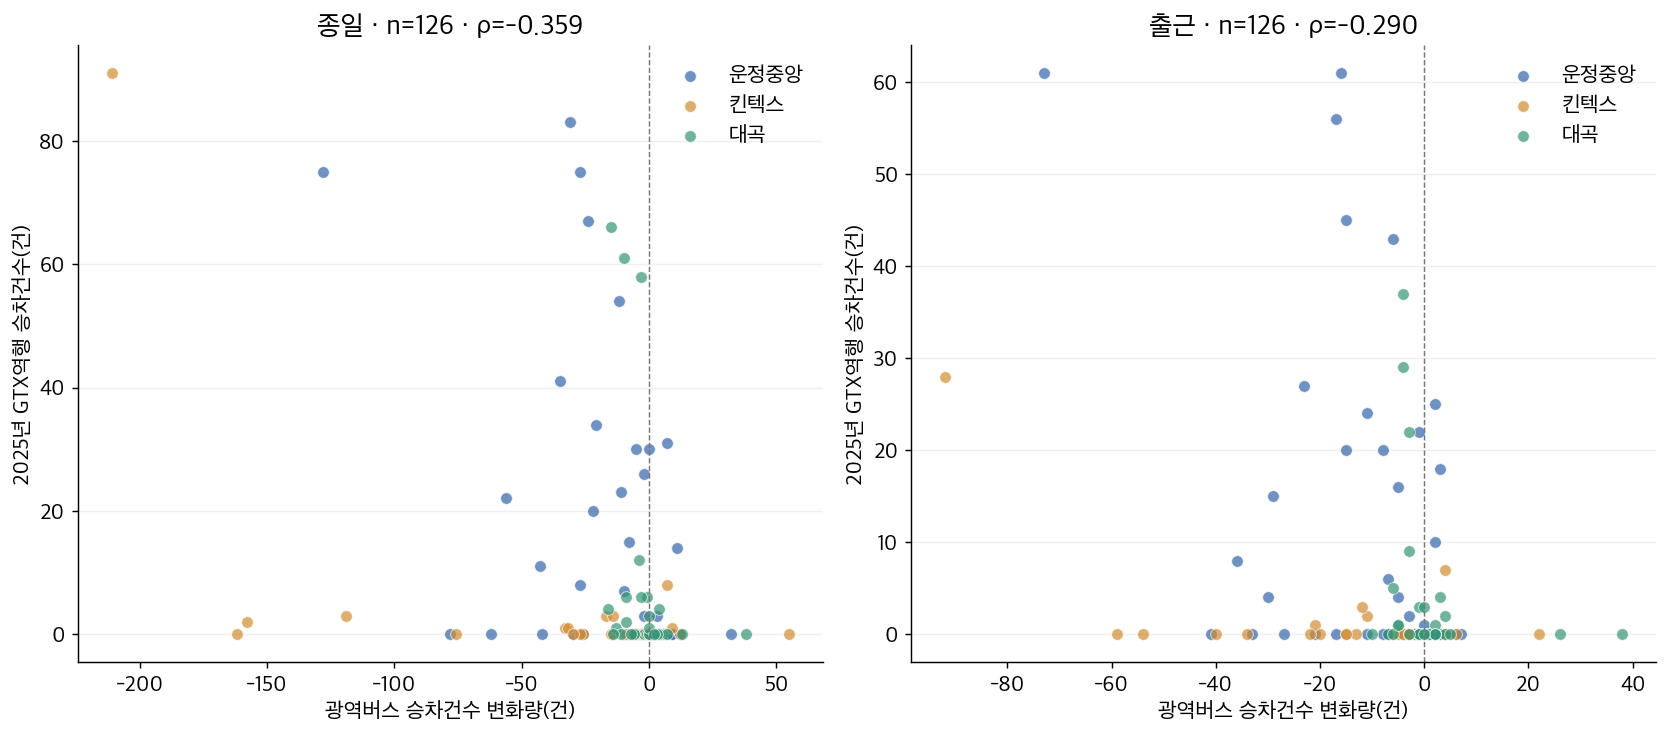

In [8]:
corr_rows_013=[]
for period,delta,target in [('종일','Δ광역','GTX역행 2025'),('출근','Δ광역 출근','GTX역행 2025 출근')]:
    for station in ['전체',*ORDER_013]:
        part=feeder_013 if station=='전체' else feeder_013.loc[feeder_013['권역'].eq(station)]
        assert part[[delta,target]].notna().all().all()
        rho,p=spearmanr(part[delta],part[target])
        corr_rows_013.append({'시간대':period,'권역':station,'격자 수':len(part),
            '광역 변화량 합계':int(part[delta].sum()),'2025 GTX역행 합계':int(part[target].sum()),
            'Spearman ρ':rho,'p값':p,'5% 유의':bool(p<.05)})
corr_013=pd.DataFrame(corr_rows_013)
assert corr_013.loc[corr_013['권역'].eq('전체'),'격자 수'].eq(126).all()
display(corr_013.round(6))
fig,axes=plt.subplots(1,2,figsize=(13,5.8))
for ax,(period,delta,target) in zip(axes,[('종일','Δ광역','GTX역행 2025'),('출근','Δ광역 출근','GTX역행 2025 출근')]):
    for station in ORDER_013:
        part=feeder_013.loc[feeder_013['권역'].eq(station)]
        ax.scatter(part[delta],part[target],label=station,color=STATION_COLORS_013[station],
                   alpha=.7,s=42,edgecolor='white',linewidth=.5)
    v=corr_013.loc[corr_013['시간대'].eq(period)&corr_013['권역'].eq('전체')].iloc[0]
    ax.axvline(0,color='#777777',ls='--',lw=.8)
    ax.set_xlabel('광역버스 승차건수 변화량(건)')
    ax.set_ylabel('2025년 GTX역행 승차건수(건)')
    ax.set_title(f"{period} · n=126 · ρ={v['Spearman ρ']:.3f}")
    ax.legend(frameon=False);axes_style_013(ax)
fig.tight_layout();plt.show()

### 출근시간 권역별 두 지표 함께 보기

위는 광역버스 **변화량**, 아래는 GTX역행 **2025년 이용 수준**이다. 두 값의 크기가 유사하더라도 전환 인원·대체율로 계산하지 않는다. 서로 다른 세로축을 사용한다.

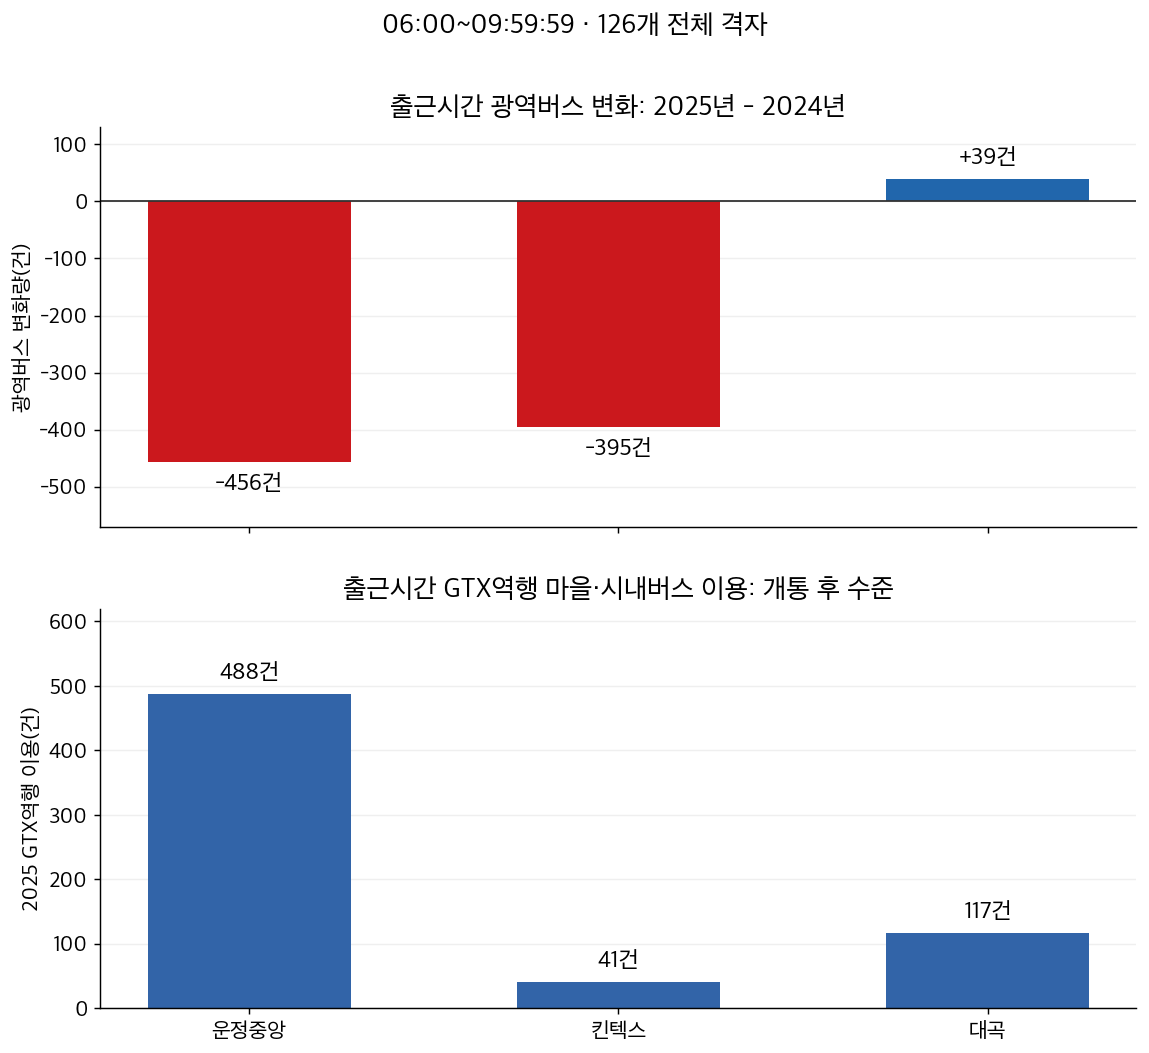

In [9]:
fig,axes=plt.subplots(2,1,figsize=(9,8),sharex=True)
vals=broad_region_013['변화량'];bars=axes[0].bar(ORDER_013,vals,color=['#CB181D' if v<0 else '#2166AC' if v>0 else '#AAAAAA' for v in vals],width=.55)
axes[0].axhline(0,color='#333333',lw=1)
for bar,v in zip(bars,vals):
    axes[0].annotate(f'{int(v):+,}건',(bar.get_x()+bar.get_width()/2,v),xytext=(0,-6 if v<0 else 6),
                     textcoords='offset points',ha='center',va='top' if v<0 else 'bottom',fontsize=13,fontweight='bold')
axes[0].set_ylim(-570,130);axes[0].set_ylabel('광역버스 변화량(건)');axes[0].set_title('출근시간 광역버스 변화: 2025년 - 2024년')
vals=feeder_region_013['출근2025'];bars=axes[1].bar(ORDER_013,vals,color='#3264A8',width=.55)
axes[1].bar_label(bars,labels=[f'{int(v):,}건' for v in vals],padding=6,fontsize=13,fontweight='bold')
axes[1].set_ylim(0,620);axes[1].set_ylabel('2025 GTX역행 이용(건)');axes[1].set_title('출근시간 GTX역행 마을·시내버스 이용: 개통 후 수준')
for ax in axes:axes_style_013(ax)
fig.suptitle(TIME_LABEL_013+' · 126개 전체 격자',fontsize=15,y=1.01)
fig.tight_layout(h_pad=2.0);plt.show()

## 7. 표본과 결과 요약

- **종일을 주 분석, 출근시간을 추가 분석**으로 제시한다. 유의성이 더 높은 시간대를 주모형으로 선택하지 않는다.
- 광역버스 출근 OLS는 113개이며, 5% 유의 4개(보행시간·주거지역 비율·경쟁 목적지 비율·IC 거리) 중 주거지역만 가설과 반대다. 통행시간은 10%에서 유의하다.
- 마을·시내버스는 2025년 이용 수준을 설명한다. 출근시간 OLS도 126개를 유지하며, 보행시간·연면적·철도역 수·운정 더미가 5%에서 유의하다.
- 순위상관은 종일·출근 각각 126개다. 광역버스 감소와 GTX역행 이용이 함께 나타나는 경향을 제시하되 실제 GTX 전환 인원은 추정하지 않는다.
- 합성 교통카드 자료의 한 날짜씩 비교이며, 시간에 따른 다른 변화·노선 공급 변화·공간적 자기상관을 완전히 분리하지 못한다. 모형의 p값은 해당 OLS/상관 추정 방법에 따른 탐색적 통계량이다.

In [10]:
sample_scope_013=pd.DataFrame([
    ['광역버스 종일 집계',126,'승차건수·변화량'],
    ['광역버스 출근 집계',len(morning_013),'승차건수·변화량, 0건 격자 포함'],
    ['광역버스 종일 OLS',int(broad_day_fit_013.nobs),'주 분석'],
    ['광역버스 출근 OLS',int(broad_morning_fit_013.nobs),'미정의 설명변수 13개 제외, 추가 분석'],
    ['마을·시내버스 종일 OLS',int(feeder_day_fit_013.nobs),'2025년 종일 이용 수준'],
    ['마을·시내버스 출근 OLS',int(feeder_morning_fit_013.nobs),'2025년 출근 이용 수준'],
    ['종일·출근 순위상관',126,'각 시간대 126개 전체']],columns=['분석','격자 수','설명'])
display(sample_scope_013)
print('화면 출력 완료 · 원자료·기존 결과표 수정 없음 · CSV/그림 파일 별도 저장 없음')

화면 출력 완료 · 원자료·기존 결과표 수정 없음 · CSV/그림 파일 별도 저장 없음


,분석,격자 수,설명
0,광역버스 종일 집계,126,승차건수·변화량
1,광역버스 출근 집계,126,"승차건수·변화량, 0건 격자 포함"
2,광역버스 종일 OLS,126,주 분석
3,광역버스 출근 OLS,113,"미정의 설명변수 13개 제외, 추가 분석"
4,마을·시내버스 종일 OLS,126,2025년 종일 이용 수준
5,마을·시내버스 출근 OLS,126,2025년 출근 이용 수준
6,종일·출근 순위상관,126,각 시간대 126개 전체


## 8. 정책적 시사점: 광역버스와 GTX의 역할 분담

현재 결과는 **광역버스와 GTX·연계버스의 역할 분담을 검토할 근거**를 제공한다. 다만 실제 승객의 수단 전환이나 노선 재편의 효과, 최적 배차를 직접 추정한 결과는 아니다. 다음 제안은 모두 **추가 수요·공급 검토가 필요한 정책적 시사점**이다.

### 8-1. 광역버스 운영에서 검토할 사항

| 검토 방향 | 분석 근거 | 해석 및 검토 범위 |
|---|---|---|
| GTX역 인근과 원거리 지역의 역할 구분 | 광역버스 변화량 OLS에서 보행시간 계수는 종일·출근 모두 양(+)이며 유의하다. 종일 운정중앙에서 보행 20분 이하 구간의 변화율은 −47.5%, 50분 초과는 −6.1%다. | GTX 접근성이 좋은 지역은 기존 광역버스와의 중복 서비스를 점검하고, 먼 지역은 직접 연결 기능을 검토한다. 가까운 지역의 노선을 일괄 감축하거나 먼 지역의 노선을 일괄 유지할 근거는 아니다. |
| GTX와 목적지가 덜 겹치는 직접 연결 기능 검토 | 경쟁 목적지 비율 계수는 종일·출근 모두 음(−)이며 5%에서 유의하다. | GTX가 직접 연결하지 못하는 목적지의 광역버스 기능을 검토한다. 이 변수는 서울역·연신내역 반경 1km 하차 비율이므로, 비경쟁 목적지 전체의 경쟁력이 입증된 것은 아니다. |
| 대곡 권역은 일괄 감축보다 별도 검토 | 종일 광역버스 변화율은 −4.4%이며 출근시간에는 +8.9%다. | GTX 개통만을 근거로 일괄 감축하지 않고, 목적지 구성·기존 철도·버스 공급·환승 여건을 함께 검토한다. 관측된 유지가 장래에도 지속된다고 확정하지 않는다. |

### 8-2. GTX역행 마을·시내버스에서 검토할 사항

| 검토 방향 | 분석 근거 | 해석 및 검토 범위 |
|---|---|---|
| 도보로 접근하기 부담스러운 지역의 연계 여건 점검 | 종일 20분 초과~50분 이하 구간의 격자당 GTX역행 이용은 운정중앙 약 20.7건, 대곡 10.0건, 킨텍스 7.4건이다. 50분 초과는 약 0.1~1.4건이다. | 20~50분 구간은 연계 교통 점검 대상의 예시다. 관측 이용은 현재 노선·배차의 영향을 받으므로 **최적 연계 범위가 20~50분이라는 결론이나 50분 초과 지역에 수요가 없다는 결론은 내리지 않는다.** 운정 20분 이하의 평균은 37.3건으로 더 높다. |
| 건축물 밀집 지역과 기존 철도 접근 여건 검토 | 연면적 계수는 종일·출근 모두 양(+)이고 5%에서 유의하다. 기존 철도역 수 계수는 음(−)이며 종일에는 10%, 출근에는 5%에서 유의하다. | 철도 접근성이 낮은 밀집 지역을 대상으로 잠재수요와 기존 버스 공급을 함께 확인하여 연계 노선 보완을 검토한다. 기존 철도역 수는 실제 철도 서비스 수준 전체를 나타내지는 않는다. |
| 출근시간 배차 적정성 점검 | 2025년 GTX역행 이용 1,015건 중 646건(63.6%)이 06:00~09:59:59에 관측되며, 운정중앙은 72.6%다. | 출근시간 이용 집중을 고려해 배차 적정성을 검토한다. 증차 규모는 혼잡도·배차간격·정원·시간대별 미충족 수요를 추가 확인한 후 판단한다. |
| 신설역 계획 및 기존역 환승 동선 점검 | 운정중앙 더미는 종일·출근 모형에서 양(+)이고 5%에서 유의하다. 답사에서는 운정중앙 환승센터와 대곡의 도로 정류장 접근 여건 차이를 관찰했다. | 신설역은 연계 노선·환승 동선을 함께 계획하는 방안을 검토하고, 기존역은 횡단·대기·이동 동선을 점검한다. 운정 더미는 여러 권역 차이를 포함하므로 **환승센터 단독 효과로 해석하지 않는다.** |
| 대곡의 특정 노선 집중도 점검 | 승차 격자 권역 기준 2025년 GTX역행 230건 중 95번이 183건(79.6%)이다. | 노선 집중이 접근 취약지역이나 혼잡을 유발하는지 확인한다. 집중 자체만으로 노선 다양화가 반드시 필요하다고 단정하지 않는다. |

**시간·공간 기준:** 보행시간 구간의 수치는 012의 **종일** 비교이며, 출근시간 회귀와 혼합하지 않는다. 출근시간은 9시대를 포함한 **06:00~09:59:59**다. 노선 집중도는 하차 GTX역이 아닌 **승차 격자의 소속 권역** 기준으로 통일했다. 이전에 제시한 대곡 84%는 이 기준의 값이 아니므로 사용하지 않는다.

### 8-3. 슬라이드용 결론 3줄

1. **GTX역 접근성과 목적지 중복 정도를 고려하여 광역버스의 직접 연결 기능과 GTX·연계버스의 역할 분담을 검토할 필요가 있다.**
2. **도보 접근이 부담스럽고 철도 접근성이 낮은 밀집 지역의 연계 여건을 점검하고, 출근시간 이용 집중을 고려한 배차 적정성 검토가 필요하다.**
3. **권역별 차이를 반영해 신설역의 연계교통 계획과 기존역의 환승 동선 개선을 검토하되, 시설의 인과효과로 단정하지 않는다.**

### 8-4. 함께 제시할 한계와 반례

- **킨텍스는 해석에서 제외하지 않는다.** 종일 광역버스는 875건 감소했지만 GTX역행 이용은 113건이며, 출근에는 각각 −395건·41건이다. 이 차이는 광역버스 감소를 관측된 연계버스 이용만으로 설명할 수 없음을 보여준다. 도보·승용차 등 다른 접근 방식과 다른 수요 변화를 추가 확인해야 한다.
- 광역버스 감소량과 GTX역행 이용량이 비슷해도 같은 승객의 전환을 뜻하지 않는다. 순위상관도 **관련성**을 보여줄 뿐이다.
- 노선 감축·유지·신설이나 배차 집중의 효과는 이번 분석에서 평가하지 않았다. 정류장별·시간대별 수요, 공급 및 혼잡 정보를 추가 검토해야 한다.
- 하루씩의 합성자료, 권역 3곳, 통제집단 부재 및 공간적 의존성의 한계를 유지한다. GTX-B·C 적용은 검증된 수요예측이 아닌 **검토 항목과 적용 가능성 탐색**으로 구분한다.


## 9. 논문용 결론 초안

아래는 종일 분석과 출근시간 추가분석을 종합한 논문 본문용 초안이다. 출근시간은 **06:00~09:59:59**로 통일한다.

### 6. 결론

#### 6.1 연구 요약

본 연구는 GTX-A 북부 구간의 운정중앙·킨텍스·대곡 권역을 대상으로, 개통 전후 광역버스 승차 변화와 GTX역행 마을·시내버스 이용의 공간적 특성을 분석하였다. 분석에는 개통 전인 2024년 10월 17일과 개통 후인 2025년 11월 6일의 합성 교통카드 자료를 사용하였으며, 광역버스 공급구조 유지 조건을 충족하는 250m 격자 126개를 대상으로 하였다. 합성자료의 이용인원 값은 두 시점 간 생성 특성이 달라 비교 집계에 제약이 있으므로, 교통카드 기록의 행 수를 승차건수로 집계하였다. 전체 시간대 분석을 주 분석으로 수행하고, 출근시간대인 06:00~09:59:59를 대상으로 추가분석을 실시하였다.

분석 결과는 다음과 같다.

첫째, 126개 격자의 광역버스 승차건수는 7,110건에서 5,517건으로 22.4% 감소하였다. 종일 변화량을 종속변수로 한 회귀분석에서는 GTX역 보행시간이 양(+)의 계수, GTX 경쟁 목적지 비율이 음(−)의 계수를 보였으며, 두 변수 모두 5% 유의수준에서 유의하였다. 이는 다른 포함 변수를 조정한 조건에서 GTX역까지 보행시간이 긴 격자일수록 승차건수 변화량이 높고, 서울역·연신내역 반경 1km 하차 비율이 높은 격자일수록 변화량이 낮은 관계가 나타났음을 의미한다. 전반적인 감소 상황에서는 이러한 결과를 각각 감소가 상대적으로 작거나 큰 경향으로 해석할 수 있다.

출근시간의 광역버스 승차건수는 3,098건에서 2,286건으로 26.2% 감소하였다. 출근시간 회귀에서도 보행시간과 경쟁 목적지 비율의 계수 방향과 5% 유의성이 유지되었다. 이와 함께 IC 도로거리는 음(−), 주거지역 비율은 양(+)의 방향으로 유의하였으며, 주거지역 비율은 당초 감소 가설과 반대였다. 평균 버스 통행시간은 음(−)의 방향으로 10% 유의수준에서 유의하였다. 종일 모형과 출근시간 모형의 수정 결정계수는 각각 0.220과 0.260이었다. 다만 종일 회귀는 126개, 출근시간 회귀는 2024년 출근 승차가 있어 통행시간과 경쟁 목적지 비율을 산출할 수 있는 113개 격자를 사용하므로, 두 수치의 차이를 시간대 변경에 따른 설명력 개선으로 단정하지 않았다.

둘째, 분석격자에서 승차하여 GTX역명 정류장에 하차한 마을·시내버스 기록은 개통 전 135건에서 개통 후 1,015건으로 증가하였다. 개통 후 이용 중 646건(63.6%)은 출근시간에 나타났다. 개통 후 GTX역행 이용 수준을 종속변수로 한 종일 회귀에서는 보행시간이 짧고 건축물 연면적이 큰 격자에서 이용이 많았으며, 운정중앙 더미도 양(+)의 방향으로 유의하였다. 출근시간 회귀에서는 이러한 관계와 함께 반경 1km 내 기존 철도역 수가 음(−)의 방향으로 5% 유의수준에서 유의하였다. 두 회귀는 모두 126개 격자를 사용하였다. 다만 운정중앙은 개통 전 역 정류장 부재 등 여건 변화가 있어, 역행 이용 증가를 동일한 서비스 조건에서의 수요 증가로만 해석하기 어렵다.

셋째, 광역버스 변화량과 개통 후 GTX역행 마을·시내버스 이용 사이에는 음의 순위상관이 나타났다. 전체 126개 격자의 Spearman 순위상관계수는 종일 −0.359, 출근시간 −0.290이었으며, 모두 통계적으로 유의하였다. 이는 광역버스 감소가 큰 격자에서 GTX역행 이용이 많이 관측되는 경향을 의미한다. 출근시간의 역별 상관은 운정중앙과 대곡에서 유의하였으나 킨텍스에서는 유의하지 않아, 이러한 경향이 모든 권역에서 동일한 강도로 나타나지는 않았다.

넷째, 권역별 광역버스 변화와 연계버스 이용 양상에는 차이가 있었다. 운정중앙에서는 종일 광역버스가 26.2% 감소하고 GTX역행 이용이 672건으로 나타났으며, 이 중 72.6%가 출근시간에 집중되었다. 종일 회귀에서 운정중앙 더미는 약 +8.2건, 출근시간 회귀에서는 약 +7.3건이었다. 대곡은 종일 광역버스 감소가 4.4%로 작았고, 출근시간에는 오히려 8.9% 증가하였다. 대곡의 종일 GTX역행 이용은 230건으로 운정중앙보다 적지만 킨텍스보다는 많았으며, 승차 권역 기준으로 95번 노선이 79.6%를 차지하였다. 반면 킨텍스는 종일 광역버스가 25.1% 감소했음에도 GTX역행 이용은 113건으로 상대적으로 적었다.

이러한 권역별 차이는 현장답사에서 관찰한 환승센터, 정류장 위치 및 연계 노선 구성과 함께 검토할 수 있다. 그러나 운정중앙 더미는 환승센터 외의 여러 권역 특성을 포함하므로 시설 자체의 효과로 해석할 수 없다. 킨텍스의 결과 역시 광역버스 감소가 관측된 연계버스 이용만으로 설명되지 않음을 보여준다.

종합하면, GTX-A 개통 전후 광역버스 승차 변화량과 개통 후 GTX역행 연계버스 이용은 GTX역 접근성 및 일부 지역·교통 특성과 관련성을 보였다. 다만 권역마다 변화 양상이 달랐으며, 본 연구의 결과는 직접적인 수단 전환의 증거가 아닌 관측된 변화와 이용 분포 사이의 관련성으로 해석해야 한다.

#### 6.2 정책적 시사점

첫째, 광역버스와 GTX·연계버스의 역할 분담을 고려한 노선 조정을 검토할 필요가 있다. 보행시간과 광역버스 변화량의 관계, 대곡과 다른 권역의 차이는 GTX 개통만을 근거로 권역 전체의 광역버스 서비스를 일괄 조정하기 어렵다는 점을 시사한다. 역 접근성뿐 아니라 기존 승차규모, 목적지 구성, 노선별 공급과 혼잡을 함께 확인한 후 지역별 조정 방향을 판단해야 한다.

둘째, GTX와 목적지가 덜 겹치는 광역버스의 직접 연결 기능을 검토할 필요가 있다. 경쟁 목적지 비율과 변화량 사이의 음의 관계는 목적지 중복 정도를 노선 검토 항목으로 활용할 수 있음을 시사한다. 다만 본 연구의 변수는 서울역·연신내역 주변 하차 비율에 한정되므로, 나머지 모든 목적지의 수요 유지나 노선 경쟁력이 확인된 것으로 확대 해석해서는 안 된다.

셋째, 도보 접근에 부담이 있고 기존 철도 접근성이 낮은 건축물 밀집 지역의 연계 교통 여건을 점검할 필요가 있다. 보행시간 구간별 관측 이용과 연면적·철도역 수의 회귀 결과를 참고하되, 20~50분 구간을 최적 연계 범위로 확정하거나 그보다 먼 지역에 수요가 없다고 판단해서는 안 된다. 관측 이용은 현재 노선과 배차의 영향을 받으므로, 미충족 수요와 실제 버스 접근시간을 추가 확인해야 한다. 또한 출근시간 이용 집중을 고려하여 배차 적정성과 혼잡을 함께 검토할 필요가 있다.

넷째, 신설역의 계획 단계에서는 연계 노선과 환승 동선을 함께 검토하고, 기존 환승역에서는 정류장부터 역 출입구·개찰구까지의 접근 여건을 점검할 필요가 있다. 운정중앙과 대곡의 비교는 권역별 연계 이용의 차이를 보여주지만, 어느 시설이 그 차이를 유발했는지는 분리하지 못한다. 따라서 GTX-B·C 노선의 계획이나 기존역 개선에는 본 연구의 결과를 검토 항목으로 활용하고, 구체적인 시설·노선 대안의 효과는 별도로 평가해야 한다.

#### 6.3 연구의 한계와 향후 과제

본 연구의 한계는 다음과 같다.

첫째, 개통 전후 각 하루의 합성 교통카드 자료를 사용하였으므로 일별 변동, 계절·날씨 및 다른 교통 여건 변화의 영향을 분리하기 어렵다. 승차건수 집계는 합성 이용인원 값의 비교 문제를 줄이지만, 합성자료 자체의 제약을 해소하거나 기록 한 건을 실제 이용자 한 명으로 확정하는 것은 아니다.

둘째, 두 날짜의 기록을 동일 이용자로 연결할 수 없고 GTX 실제 탑승 여부도 확인할 수 없다. 특히 기존 철도 환승역인 대곡의 역명 정류장 하차는 다른 철도 이용일 수도 있다. 따라서 광역버스 감소와 GTX역행 버스 이용의 동반 분포를 개인의 수단 전환이나 GTX 개통의 인과효과로 해석할 수 없다.

셋째, 분석 대상이 역 3곳으로 제한되어 환승시설과 지역 특성의 영향을 분리하기 어렵다. 운정중앙 더미는 연계 노선 개편, 주변 토지이용 등 다양한 차이를 함께 포함하며 환승센터 단독 효과를 나타내지 않는다. 광역버스에서 적용한 공급구조 유지 조건이 마을·시내버스의 공급까지 유지되었음을 의미하지도 않는다.

넷째, 종일과 출근시간 광역버스 회귀의 분석 표본이 달라 시간대별 계수·유의성·설명력 차이에는 표본 구성의 차이가 함께 반영될 수 있다. 포함 변수만으로 설명되지 않는 변화가 남아 있고, 개통 전 수요 규모, 배차 변화 및 공간적 의존성도 결과에 영향을 줄 수 있다. HC3 표준오차는 이분산에 대응하지만 이러한 모든 문제를 해결하지는 않는다.

향후 연구에서는 본 연구에서 확인한 GTX-A 개통 전후 변화를 바탕으로, GTX-B·C 노선 개통 전에 개통 후의 광역버스 이용 변화와 GTX역 연계버스 이용을 시뮬레이션하는 것을 목표로 한다. 이를 위해 GTX역 보행시간, GTX와 겹치는 목적지 비율, 건축물 연면적, 기존 철도역 수와 접근 여건 등 본 연구에서 관련성을 확인한 요인과 현장답사에서 파악한 환승 연계 여건을 B·C 노선 역 주변 지역에 적용하여, 광역버스 이용 변화가 크게 나타날 수 있는 지역과 연계 교통 검토가 필요한 지역을 개통 전에 진단하고자 한다. 다만 노선과 지역에 따라 여건이 다르므로, 시뮬레이션의 신뢰성을 높이려면 분석 기간과 대상 역을 늘린 자료로 모형을 보완하고 적용 지역에 맞게 보정하며, B·C 노선 개통 후 실제 자료와 비교하여 검증하는 과정이 함께 필요하다. 아울러 원자료 또는 이용자 설문을 통해 개인 단위 이동 변화를 확인하고, 환승 거리와 시간 등 환승 편의성을 정량적으로 측정하는 연구도 병행할 필요가 있다. 이 시뮬레이션은 향후 연구 목표이며, 현재의 3개 역 자료로 B·C 노선의 수요 변화를 검증된 수준으로 예측할 수 있음을 뜻하지는 않는다.
